In [1]:
# PART A: Prepare the data 
import pandas as pd
import numpy as np

df = pd.read_csv("data/inspection_level_plus.csv",
                 dtype={"ZIPCODE": "string", "BBL": "string", "ZIP5": "string"},
                 parse_dates=["INSPECTION DATE"], low_memory=False)
print(df.shape)
print(list(df.columns))
print(df["SCORE"].describe())
print(df["BORO"].value_counts(dropna=False))
print(df["INSPECTION DATE"].dt.year.value_counts().sort_index())

/Users/ana.abreu/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


(93292, 56)
['REPRESENTATIVE_SOURCE_ROW_ID', 'CAMIS', 'DBA', 'BORO', 'BUILDING', 'STREET', 'ZIPCODE', 'PHONE', 'CUISINE DESCRIPTION', 'INSPECTION DATE', 'ACTION', 'SCORE', 'GRADE', 'GRADE DATE', 'RECORD DATE', 'INSPECTION TYPE', 'Latitude', 'Longitude', 'Community Board', 'Council District', 'Census Tract', 'BIN', 'BBL', 'NTA', 'Location', 'AWAITING_INSPECTION', 'BORO_UNKNOWN', 'ZERO_COORDINATES', 'BBL_INCOMPLETE', 'GRADE_CATEGORY', '_has_violation_code', '_is_critical_violation', '_is_non_critical_violation', 'violation_record_count', 'total_violation_count', 'missing_violation_code_row_count', 'critical_violation_count', 'non_critical_violation_count', 'not_applicable_flag_record_count', 'unique_violation_code_count', 'violation_description_record_count', 'score_band', 'critical_violation_pct', 'bldgclass', 'landuse', 'lotarea', 'bldgarea', 'numfloors', 'unitsres', 'unitstotal', 'assesstot', 'yearbuilt', 'pluto_matched', 'ZIP5', 'median_hh_income', 'population']
count    82956.000000

In [2]:
# Create the two targets
df["LOG_SCORE"] = np.log1p(df["SCORE"])
df["SCORE_14PLUS"] = np.where(df["SCORE"].notna(), (df["SCORE"] >= 14).astype(int), np.nan)

scored = df[df["SCORE"].notna()]
print("Scored inspections:", len(scored))
print("SCORE_14PLUS rate (share with score 14+):", round(scored["SCORE_14PLUS"].mean() * 100, 1), "%")
print(scored[["SCORE", "LOG_SCORE"]].describe())
print("Skew SCORE:", round(scored["SCORE"].skew(), 2), "| Skew LOG_SCORE:", round(scored["LOG_SCORE"].skew(), 2))

Scored inspections: 82956
SCORE_14PLUS rate (share with score 14+): 40.1 %
              SCORE     LOG_SCORE
count  82956.000000  82956.000000
mean      17.890388      2.656265
std       14.922439      0.806754
min        0.000000      0.000000
25%        9.000000      2.302585
50%       13.000000      2.639057
75%       24.000000      3.218876
max      214.000000      5.370638
Skew SCORE: 2.3 | Skew LOG_SCORE: -0.75


In [3]:
# Build history features from earlier scored inspections
df = df.sort_values(["CAMIS", "INSPECTION DATE"]).reset_index(drop=True)

# only scored inspections count as "earlier inspections"
s = df[df["SCORE"].notna()]
gs = s.groupby("CAMIS")
hist = pd.DataFrame({
    "prev_score": gs["SCORE"].shift(1),
    "prev_critical": gs["critical_violation_count"].shift(1),
    "prev_total_viol": gs["total_violation_count"].shift(1),
    "days_since_last": gs["INSPECTION DATE"].diff().dt.days,
    "n_prior_inspections": gs.cumcount(),
    "days_since_first": (s["INSPECTION DATE"] - gs["INSPECTION DATE"].transform("min")).dt.days,
}, index=s.index)
df = df.drop(columns=[c for c in hist.columns if c in df.columns]).join(hist)

# chain flag: same name at 5 or more different locations
dba = df["DBA"].str.upper().str.strip()
df["chain"] = (df.groupby(dba)["CAMIS"].transform("nunique") >= 5).astype(int)

new_cols = ["prev_score", "prev_critical", "prev_total_viol", "days_since_last",
            "n_prior_inspections", "days_since_first", "chain"]
print((df.loc[df["SCORE"].notna(), new_cols].isna().mean() * 100).round(1))
print("Scored rows with 0 days since last:", int((df["days_since_last"] == 0).sum()))
print("Chain share:", round(df["chain"].mean() * 100, 1), "%")

prev_score             33.3
prev_critical          33.3
prev_total_viol        33.3
days_since_last        33.3
n_prior_inspections     0.0
days_since_first        0.0
chain                   0.0
dtype: float64
Scored rows with 0 days since last: 1
Chain share: 17.0 %


In [4]:
# Keep the rows we will model
d = df[df["SCORE"].notna()].copy()
n_scored = len(d)
d = d[d["INSPECTION DATE"].dt.year.between(2023, 2026)]
d = d[d["BORO"].astype(str) != "0"]

d["year"] = d["INSPECTION DATE"].dt.year
d["month"] = d["INSPECTION DATE"].dt.month
d["has_history"] = d["prev_score"].notna().astype(int)

print("Rows kept:", len(d), "of", n_scored, "scored inspections")
print("SCORE_14PLUS rate:", round(d["SCORE_14PLUS"].mean() * 100, 1), "%")
print(d["year"].value_counts().sort_index())
print(d["BORO"].value_counts())
print("History available:", round(d["has_history"].mean() * 100, 1), "%")

Rows kept: 78249 of 82956 scored inspections
SCORE_14PLUS rate: 40.5 %
year
2023    13941
2024    22438
2025    24610
2026    17260
Name: count, dtype: int64
BORO
Manhattan        29612
Brooklyn         20140
Queens           18360
Bronx             7408
Staten Island     2729
Name: count, dtype: int64
History available: 69.1 %


In [5]:
# Choose the predictors and split the data (70/30)
from sklearn.model_selection import train_test_split

# cuisine: top 15 + Other
top_cuisines = d["CUISINE DESCRIPTION"].value_counts().head(15).index
d["cuisine"] = np.where(d["CUISINE DESCRIPTION"].isin(top_cuisines), d["CUISINE DESCRIPTION"], "Other")

# building and neighborhood features
d["bldg_age"] = d["year"] - d["yearbuilt"]
d["bldg_known"] = d["yearbuilt"].notna().astype(int)
d["income_known"] = d["median_hh_income"].notna().astype(int)

num_cols = ["year", "month", "prev_score", "prev_critical", "prev_total_viol", "days_since_last",
            "n_prior_inspections", "days_since_first", "chain", "has_history",
            "bldg_age", "numfloors", "unitsres", "unitstotal", "bldgarea", "lotarea", "assesstot",
            "bldg_known", "median_hh_income", "population", "income_known"]
cat_cols = ["BORO", "INSPECTION TYPE", "cuisine"]

X = pd.get_dummies(d[num_cols + cat_cols], columns=cat_cols, drop_first=True, dtype=int)
y_14plus = d["SCORE_14PLUS"].astype(int)
y_log = d["LOG_SCORE"]

# 70/30 split, same rows for every model
train_idx, test_idx = train_test_split(d.index, test_size=0.3, stratify=y_14plus, random_state=42)
X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()

# fill missing values with the TRAINING medians
med = X_train.median()
X_train = X_train.fillna(med)
X_test = X_test.fillna(med)

print("X shape:", X.shape)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("SCORE_14PLUS rate train:", round(y_14plus.loc[train_idx].mean() * 100, 1), "% | test:", round(y_14plus.loc[test_idx].mean() * 100, 1), "%")
print("Missing left:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
print(d["bldg_age"].describe().round(1))

X shape: (78249, 55)
Train: (54774, 55) | Test: (23475, 55)
SCORE_14PLUS rate train: 40.5 % | test: 40.5 %
Missing left: 0
count    75622.0
mean        89.2
std         34.3
min         -1.0
25%         74.0
50%         95.0
75%        109.0
max        307.0
Name: bldg_age, dtype: float64


In [6]:
# PART B: Check the variables with VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xc = sm.add_constant(X_train.astype(float))
vif = pd.DataFrame({"variable": Xc.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
print(vif[vif["variable"] != "const"].sort_values("VIF", ascending=False).head(15).round(2))

/Users/ana.abreu/anaconda3/lib/python3.11/site-packages/statsmodels/regression/linear_model.py:1781: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


                                             variable    VIF
14                                         unitstotal  56.11
13                                           unitsres  54.98
26  INSPECTION TYPE_Cycle Inspection / Initial Ins...  54.65
27   INSPECTION TYPE_Cycle Inspection / Re-inspection  35.89
37  INSPECTION TYPE_Pre-permit (Operational) / Ini...  26.32
17                                          assesstot  24.00
16                                            lotarea  13.83
38  INSPECTION TYPE_Pre-permit (Operational) / Re-...   8.75
15                                           bldgarea   8.00
8                                    days_since_first   7.09
3                                          prev_score   6.40
4                                       prev_critical   5.87
5                                     prev_total_viol   5.45
7                                 n_prior_inspections   5.03
23                                     BORO_Manhattan   4.56


In [7]:
# Fix the overlap and check VIF again
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)


num_cols2 = [c for c in num_cols if c not in ["unitsres", "assesstot"]]

# dummies, using the MOST COMMON category of each variable as the reference
X = pd.get_dummies(d[num_cols2 + cat_cols], columns=cat_cols, dtype=int)
for col in cat_cols:
    ref = d[col].value_counts().index[0]
    print("Reference for", col, ":", ref)
    X = X.drop(columns=f"{col}_{ref}")


X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()
med = X_train.median()
X_train = X_train.fillna(med)
X_test = X_test.fillna(med)

# VIF again
Xc = sm.add_constant(X_train.astype(float))
vif = pd.DataFrame({"variable": Xc.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
print("X shape:", X.shape)
print(vif[vif["variable"] != "const"].sort_values("VIF", ascending=False).head(10).round(2))

Reference for BORO : Manhattan
Reference for INSPECTION TYPE : Cycle Inspection / Initial Inspection
Reference for cuisine : Other
X shape: (78249, 53)
               variable   VIF
8      days_since_first  7.09
3            prev_score  6.40
4         prev_critical  5.87
5       prev_total_viol  5.45
7   n_prior_inspections  5.03
14             bldgarea  4.50
6       days_since_last  3.81
10          has_history  3.75
15              lotarea  3.35
12            numfloors  2.47


In [8]:
# Prepare the data for the logistic regression
# drop very rare dummy columns (fewer than 50 training rows), for ALL models
dummy_cols = [c for c in X_train.columns if c not in num_cols2]
counts = X_train[dummy_cols].sum().sort_values()
print("Smallest categories in training:")
print(counts.head(8))

rare = counts[counts < 50].index.tolist()
const = [c for c in X_train.columns if X_train[c].nunique() <= 1]
drop_cols = sorted(set(rare + const))
print("\nDropping:", drop_cols)
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

# the target for the same rows
y_train = y_14plus.loc[train_idx]
y_test = y_14plus.loc[test_idx]

# standardize the numeric columns with the training  mean and std
cont = ["year", "month", "prev_score", "prev_critical", "prev_total_viol", "days_since_last",
        "n_prior_inspections", "days_since_first", "bldg_age", "numfloors", "unitstotal",
        "bldgarea", "lotarea", "median_hh_income", "population"]
mu, sd = X_train[cont].mean(), X_train[cont].std()
Xs_train, Xs_test = X_train.copy(), X_test.copy()
Xs_train[cont] = (X_train[cont] - mu) / sd
Xs_test[cont] = (X_test[cont] - mu) / sd

print("\nX_train:", X_train.shape, "| X_test:", X_test.shape)
print("Standardized train mean (max):", round(Xs_train[cont].mean().abs().max(), 3),
      "| std range:", round(Xs_train[cont].std().min(), 3), "to", round(Xs_train[cont].std().max(), 3))

Smallest categories in training:
INSPECTION TYPE_Inter-Agency Task Force / Re-inspection                          1
INSPECTION TYPE_Pre-permit (Non-operational) / Second Compliance Inspection      3
INSPECTION TYPE_Cycle Inspection / Second Compliance Inspection                 20
INSPECTION TYPE_Pre-permit (Non-operational) / Compliance Inspection            23
INSPECTION TYPE_Pre-permit (Operational) / Second Compliance Inspection         36
INSPECTION TYPE_Pre-permit (Non-operational) / Re-inspection                   142
INSPECTION TYPE_Cycle Inspection / Compliance Inspection                       270
INSPECTION TYPE_Pre-permit (Operational) / Reopening Inspection                304
dtype: int64

Dropping: ['INSPECTION TYPE_Cycle Inspection / Second Compliance Inspection', 'INSPECTION TYPE_Inter-Agency Task Force / Re-inspection', 'INSPECTION TYPE_Pre-permit (Non-operational) / Compliance Inspection', 'INSPECTION TYPE_Pre-permit (Non-operational) / Second Compliance Inspection', '

In [9]:
# Fit the logistic regression for SCORE_14PLUS
Xc_train = sm.add_constant(Xs_train.astype(float))
try:
    logit_14plus = sm.Logit(y_train, Xc_train).fit(maxiter=200, disp=0)
    print("Method: newton")
except np.linalg.LinAlgError:
    logit_14plus = sm.Logit(y_train, Xc_train).fit(method="bfgs", maxiter=1000, disp=0)
    print("Method: bfgs")

res = pd.DataFrame({"coef": logit_14plus.params,
                    "odds_ratio": np.exp(logit_14plus.params),
                    "p_value": logit_14plus.pvalues,
                    "abs_z": logit_14plus.tvalues.abs()}).drop("const")
print("Converged:", logit_14plus.mle_retvals["converged"])
print(res.sort_values("abs_z", ascending=False).head(15).round(3).to_string())

Method: newton
Converged: True
                                                                  coef  odds_ratio  p_value   abs_z
INSPECTION TYPE_Cycle Inspection / Reopening Inspection         -2.348       0.096      0.0  21.638
days_since_first                                                -0.545       0.580      0.0  21.533
n_prior_inspections                                              0.417       1.518      0.0  19.217
INSPECTION TYPE_Cycle Inspection / Re-inspection                -0.636       0.530      0.0  19.073
chain                                                           -0.491       0.612      0.0  16.823
INSPECTION TYPE_Pre-permit (Operational) / Reopening Inspection -2.393       0.091      0.0  15.170
year                                                             0.165       1.180      0.0  13.238
INSPECTION TYPE_Pre-permit (Operational) / Re-inspection        -0.790       0.454      0.0  12.938
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection    -4.49

[[11446  2525]
 [ 5968  3536]]
              precision    recall  f1-score   support

  score 0-13      0.657     0.819     0.729     13971
   score 14+      0.583     0.372     0.454      9504

    accuracy                          0.638     23475
   macro avg      0.620     0.596     0.592     23475
weighted avg      0.627     0.638     0.618     23475

Baseline accuracy (always predict score 0-13): 0.595
AUC: 0.674


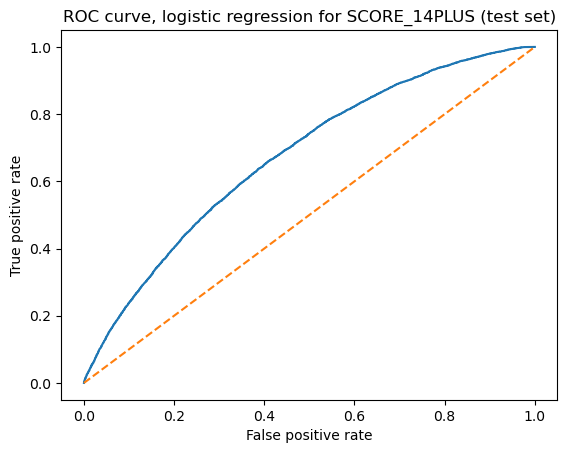

In [10]:
# Test the logistic regression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve, classification_report
import matplotlib.pyplot as plt

Xc_test = sm.add_constant(Xs_test.astype(float), has_constant="add")
p_logit = logit_14plus.predict(Xc_test)
pred_logit = (p_logit >= 0.5).astype(int)

print(confusion_matrix(y_test, pred_logit))
print(classification_report(y_test, pred_logit, target_names=["score 0-13", "score 14+"], digits=3))
print("Baseline accuracy (always predict score 0-13):", round(1 - y_test.mean(), 3))
print("AUC:", round(roc_auc_score(y_test, p_logit), 3))

fpr, tpr, _ = roc_curve(y_test, p_logit)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve, logistic regression for SCORE_14PLUS (test set)")
plt.show()

In [11]:
# Do the building and Census columns help?
geo_cols = ["bldg_age", "numfloors", "unitstotal", "bldgarea", "lotarea", "bldg_known",
            "median_hh_income", "population", "income_known"]
base_cols = [c for c in Xs_train.columns if c not in geo_cols]

logit_base = sm.Logit(y_train, sm.add_constant(Xs_train[base_cols].astype(float))).fit(maxiter=200, disp=0)
p_base = logit_base.predict(sm.add_constant(Xs_test[base_cols].astype(float), has_constant="add"))

print("AUC without building/Census:", round(roc_auc_score(y_test, p_base), 4))
print("AUC with building/Census:   ", round(roc_auc_score(y_test, p_logit), 4))
print("Accuracy without:", round(accuracy_score(y_test, (p_base >= 0.5).astype(int)), 4))
print("Accuracy with:   ", round(accuracy_score(y_test, pred_logit), 4))

print(res.loc[geo_cols, ["coef", "odds_ratio", "p_value"]].round(3))

AUC without building/Census: 0.6698
AUC with building/Census:    0.6735
Accuracy without: 0.6371
Accuracy with:    0.6382
                   coef  odds_ratio  p_value
bldg_age          0.039       1.040    0.000
numfloors        -0.027       0.973    0.069
unitstotal        0.042       1.043    0.000
bldgarea         -0.086       0.917    0.000
lotarea           0.027       1.027    0.187
bldg_known        0.365       1.440    0.000
median_hh_income -0.048       0.953    0.000
population        0.020       1.021    0.079
income_known      0.220       1.246    0.009


[[12851  1120]
 [ 8037  1467]]
              precision    recall  f1-score   support

  score 0-13      0.615     0.920     0.737     13971
   score 14+      0.567     0.154     0.243      9504

    accuracy                          0.610     23475
   macro avg      0.591     0.537     0.490     23475
weighted avg      0.596     0.610     0.537     23475

AUC: 0.6
chain                                                            0.358
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection     0.220
days_since_first                                                 0.196
INSPECTION TYPE_Pre-permit (Operational) / Initial Inspection    0.114
prev_score                                                       0.035
year                                                             0.024
cuisine_Donuts                                                   0.023
cuisine_Latin American                                           0.018
month                                                            

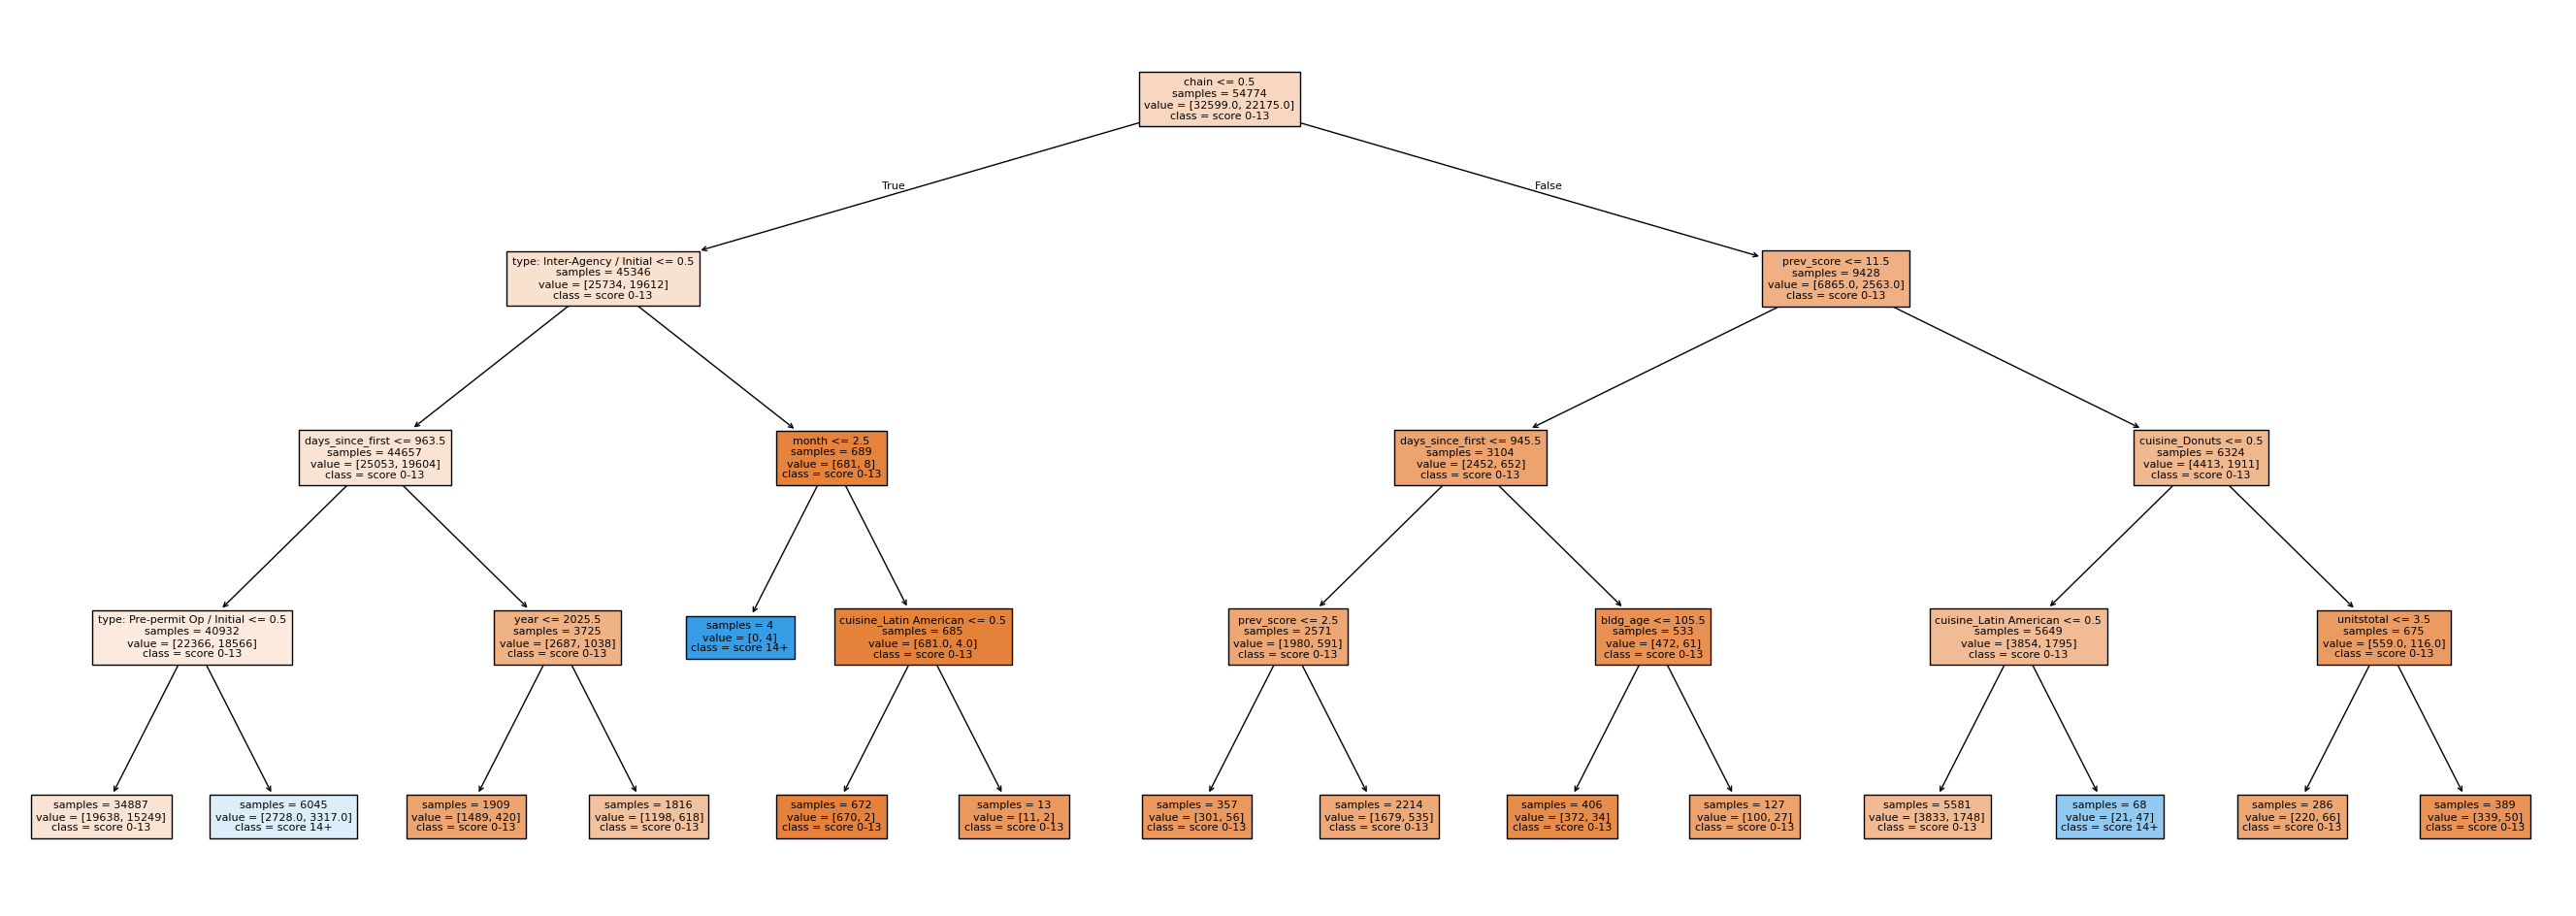

In [12]:
# PART D: Classification decision tree for SCORE_14PLUS
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree_14plus = DecisionTreeClassifier(max_depth=4, min_samples_split=30, random_state=0)
tree_14plus.fit(X_train, y_train)

pred_tree = tree_14plus.predict(X_test)
p_tree = tree_14plus.predict_proba(X_test)[:, 1]
print(confusion_matrix(y_test, pred_tree))
print(classification_report(y_test, pred_tree, target_names=["score 0-13", "score 14+"], digits=3))
print("AUC:", round(roc_auc_score(y_test, p_tree), 3))

imp = pd.Series(tree_14plus.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.head(10).round(3))

# short names, only for the picture
short_names = [c.replace("INSPECTION TYPE_", "type: ").replace(" Inspection", "")
                .replace("Inter-Agency Task Force", "Inter-Agency")
                .replace("Pre-permit (Operational)", "Pre-permit Op") for c in X_train.columns]

plt.figure(figsize=(34, 12))
plt.title("Classification Decision Tree: predicting SCORE_14PLUS (score 14 or more), max depth 4", fontsize=18)
plot_tree(tree_14plus, feature_names=short_names, class_names=["score 0-13", "score 14+"],
          filled=True, fontsize=8, impurity=False, precision=1)
plt.show()

In [13]:
# Tune the classification tree with GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid = {"max_depth": [3, 4, 5, 6, 8, 10],
              "min_samples_split": [30, 100, 300]}

grid_tree = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid,
                         cv=10, scoring="roc_auc")
grid_tree.fit(X_train, y_train)

print("Best settings:", grid_tree.best_params_)
print("Best cross-validated AUC:", round(grid_tree.best_score_, 3))

tree_tuned = grid_tree.best_estimator_
pred_tuned = tree_tuned.predict(X_test)
p_tuned = tree_tuned.predict_proba(X_test)[:, 1]
print(confusion_matrix(y_test, pred_tuned))
print(classification_report(y_test, pred_tuned, target_names=["score 0-13", "score 14+"], digits=3))
print("Test AUC:", round(roc_auc_score(y_test, p_tuned), 3))

imp_tuned = pd.Series(tree_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp_tuned.head(10).round(3))

Best settings: {'max_depth': 10, 'min_samples_split': 300}
Best cross-validated AUC: 0.658
[[12196  1775]
 [ 6921  2583]]
              precision    recall  f1-score   support

  score 0-13      0.638     0.873     0.737     13971
   score 14+      0.593     0.272     0.373      9504

    accuracy                          0.630     23475
   macro avg      0.615     0.572     0.555     23475
weighted avg      0.620     0.630     0.590     23475

Test AUC: 0.655
chain                                                            0.153
prev_score                                                       0.128
days_since_first                                                 0.113
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection     0.094
days_since_last                                                  0.072
INSPECTION TYPE_Cycle Inspection / Re-inspection                 0.059
n_prior_inspections                                              0.056
INSPECTION TYPE_Pre-permit (Operationa

In [14]:
# Choose a better cutoff using the training rows only
p_train = logit_14plus.predict(Xc_train)
fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, p_train)
best = np.argmax(tpr_tr - fpr_tr)
cut = thr_tr[best]
print("Cutoff chosen on the training rows:", round(cut, 3))
print("Share of 14+ caught on training rows:", round(tpr_tr[best], 3))
print("Share of 0-13 wrongly flagged on training rows:", round(fpr_tr[best], 3))

pred_cut = (p_logit >= cut).astype(int)
print(confusion_matrix(y_test, pred_cut))
print(classification_report(y_test, pred_cut, target_names=["score 0-13", "score 14+"], digits=3))
print("Accuracy at 0.5:", round(accuracy_score(y_test, pred_logit), 3),
      "| at the new cutoff:", round(accuracy_score(y_test, pred_cut), 3))

Cutoff chosen on the training rows: 0.411
Share of 14+ caught on training rows: 0.639
Share of 0-13 wrongly flagged on training rows: 0.39
[[8503 5468]
 [3421 6083]]
              precision    recall  f1-score   support

  score 0-13      0.713     0.609     0.657     13971
   score 14+      0.527     0.640     0.578      9504

    accuracy                          0.621     23475
   macro avg      0.620     0.624     0.617     23475
weighted avg      0.638     0.621     0.625     23475

Accuracy at 0.5: 0.638 | at the new cutoff: 0.621


In [15]:
# PART E: Linear regression for LOG_SCORE
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_train_log = y_log.loc[train_idx]
y_test_log = y_log.loc[test_idx]

ols = sm.OLS(y_train_log, Xc_train).fit()
pred_log = ols.predict(Xc_test)
base_log = np.full(len(y_test_log), y_train_log.mean())

def scores(y_true, pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "MAE": mean_absolute_error(y_true, pred),
            "R2": r2_score(y_true, pred)}

print("Test results on the LOG_SCORE scale")
print(pd.DataFrame({"Baseline (training mean)": scores(y_test_log, base_log),
                    "Linear regression": scores(y_test_log, pred_log)}).T.round(3))

y_test_score = np.expm1(y_test_log)
pred_score = np.expm1(pred_log).clip(lower=0)
base_score = np.expm1(y_train_log).mean()
print("Test results on the original SCORE scale")
print(pd.DataFrame({"Baseline (training mean)": scores(y_test_score, np.full(len(y_test_score), base_score)),
                    "Linear regression": scores(y_test_score, pred_score)}).T.round(3))

print("Train R2:", round(ols.rsquared, 3))
res_ols = pd.DataFrame({"coef": ols.params, "p_value": ols.pvalues, "abs_t": ols.tvalues.abs()}).drop("const")
print(res_ols.sort_values("abs_t", ascending=False).head(15).round(4))

Test results on the LOG_SCORE scale
                           RMSE    MAE     R2
Baseline (training mean)  0.800  0.587 -0.000
Linear regression         0.687  0.525  0.262
Test results on the original SCORE scale
                            RMSE     MAE     R2
Baseline (training mean)  15.010  10.908 -0.000
Linear regression         14.767   9.315  0.032
Train R2: 0.253
                                                      coef  p_value     abs_t
INSPECTION TYPE_Inter-Agency Task Force / Initi... -2.7262      0.0  101.6174
INSPECTION TYPE_Cycle Inspection / Reopening In... -1.3611      0.0   47.3966
INSPECTION TYPE_Pre-permit (Operational) / Reop... -1.5175      0.0   34.5782
chain                                              -0.1884      0.0   20.7389
days_since_first                                   -0.1552      0.0   19.8969
n_prior_inspections                                 0.1165      0.0   17.7181
cuisine_Coffee/Tea                                 -0.1800      0.0   15.2492
I

In [16]:
# Linear regression and Census variables
Xb_train = sm.add_constant(Xs_train[base_cols].astype(float))
Xb_test = sm.add_constant(Xs_test[base_cols].astype(float), has_constant="add")
ols_base = sm.OLS(y_train_log, Xb_train).fit()
pred_base_log = ols_base.predict(Xb_test)

comp = pd.DataFrame({"Without building/Census": scores(y_test_log, pred_base_log),
                     "With building/Census": scores(y_test_log, pred_log)}).T
print("Test results on the LOG_SCORE scale")
print(comp.round(4))
print("Adjusted R2 on training rows: without", round(ols_base.rsquared_adj, 4),
      "| with", round(ols.rsquared_adj, 4))
print(res_ols.loc[geo_cols, ["coef", "p_value"]].round(4))

Test results on the LOG_SCORE scale
                           RMSE     MAE      R2
Without building/Census  0.6908  0.5257  0.2534
With building/Census     0.6869  0.5248  0.2619
Adjusted R2 on training rows: without 0.2441 | with 0.252
                    coef  p_value
bldg_age          0.0170   0.0000
numfloors        -0.0065   0.1605
unitstotal        0.0157   0.0000
bldgarea         -0.0424   0.0000
lotarea           0.0162   0.0026
bldg_known        0.1688   0.0000
median_hh_income -0.0177   0.0000
population        0.0035   0.3529
income_known      0.2170   0.0000


Test results on the LOG_SCORE scale
                            RMSE    MAE     R2
Baseline (training mean)   0.800  0.587 -0.000
Linear regression          0.687  0.525  0.262
Regression tree (depth 4)  0.713  0.548  0.205
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection    0.717
days_since_last                                                 0.129
chain                                                           0.100
lotarea                                                         0.031
prev_score                                                      0.007
month                                                           0.006
year                                                            0.005
prev_critical                                                   0.003
prev_total_viol                                                 0.002
cuisine_Latin American                                          0.001
dtype: float64


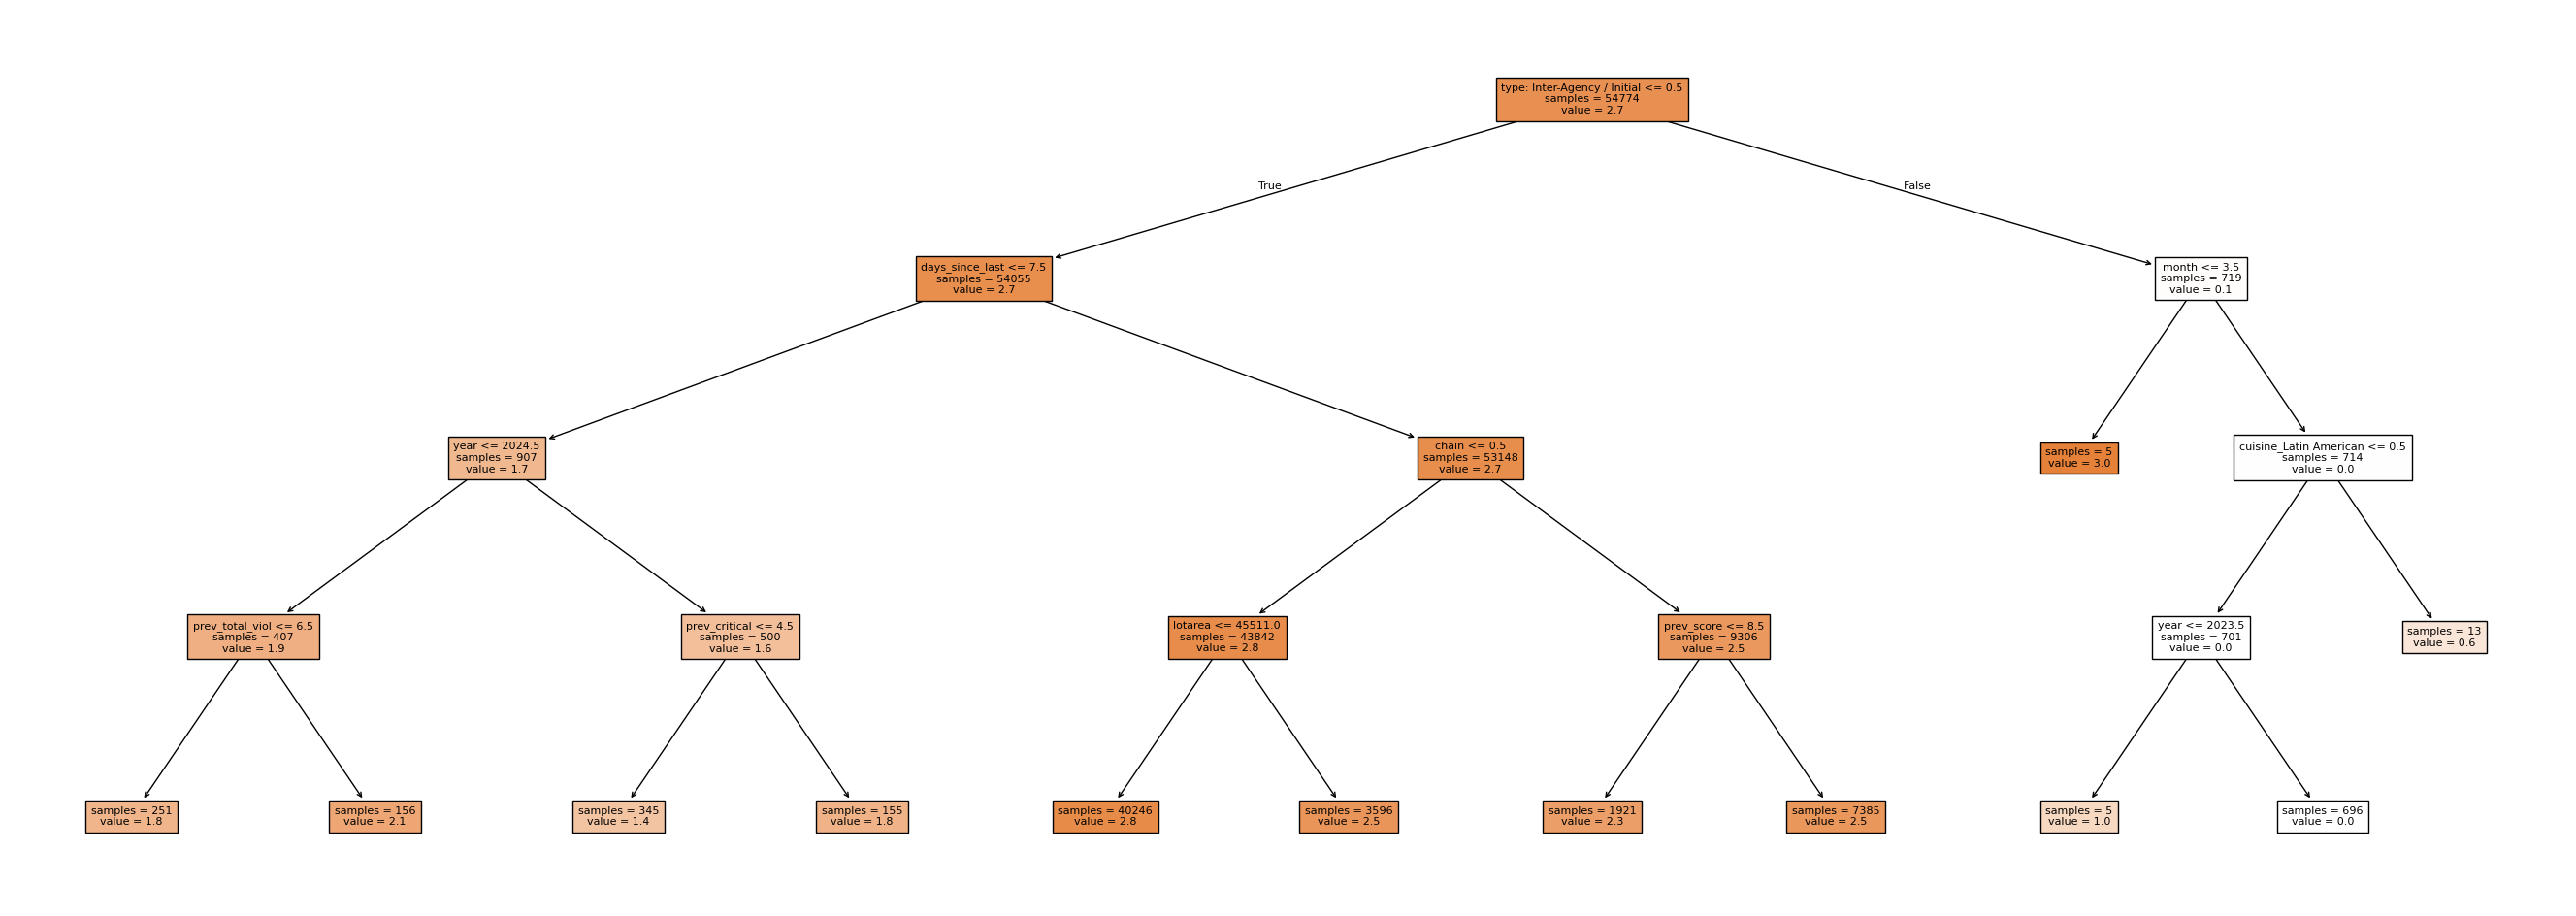

In [17]:
# PART F: Regression decision tree for LOG_SCORE
from sklearn.tree import DecisionTreeRegressor

tree_log = DecisionTreeRegressor(max_depth=4, min_samples_split=30, random_state=0)
tree_log.fit(X_train, y_train_log)
pred_tree_log = tree_log.predict(X_test)

print("Test results on the LOG_SCORE scale")
print(pd.DataFrame({"Baseline (training mean)": scores(y_test_log, base_log),
                    "Linear regression": scores(y_test_log, pred_log),
                    "Regression tree (depth 4)": scores(y_test_log, pred_tree_log)}).T.round(3))

imp_log = pd.Series(tree_log.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp_log.head(10).round(3))

plt.figure(figsize=(34, 12))
plt.title("Regression Decision Tree: predicting LOG_SCORE, max depth 4", fontsize=18)
plot_tree(tree_log, feature_names=short_names, filled=True, fontsize=8, impurity=False, precision=1)
plt.show()

In [18]:
# Tune the regression tree with GridSearchCV
param_grid_r = {"max_depth": [4, 6, 8, 10, 12, 15],
                "min_samples_split": [30, 100, 300, 1000]}
grid_tree_log = GridSearchCV(DecisionTreeRegressor(random_state=0), param_grid_r, cv=10)
grid_tree_log.fit(X_train, y_train_log)

print("Best settings:", grid_tree_log.best_params_)
print("Best cross-validated R2:", round(grid_tree_log.best_score_, 3))

tree_log_tuned = grid_tree_log.best_estimator_
pred_tree_tuned = tree_log_tuned.predict(X_test)
print("Number of leaves:", tree_log_tuned.get_n_leaves())

print("Test results on the LOG_SCORE scale")
print(pd.DataFrame({"Baseline (training mean)": scores(y_test_log, base_log),
                    "Linear regression": scores(y_test_log, pred_log),
                    "Regression tree (depth 4)": scores(y_test_log, pred_tree_log),
                    "Regression tree (tuned)": scores(y_test_log, pred_tree_tuned)}).T.round(3))

print("Test results on the original SCORE scale")
pred_tuned_score = np.expm1(pred_tree_tuned).clip(min=0)
print(pd.DataFrame({"Linear regression": scores(y_test_score, pred_score),
                    "Regression tree (tuned)": scores(y_test_score, pred_tuned_score)}).T.round(3))

imp_log_tuned = pd.Series(tree_log_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp_log_tuned.head(10).round(3))

Best settings: {'max_depth': 15, 'min_samples_split': 1000}
Best cross-validated R2: 0.237
Number of leaves: 104
Test results on the LOG_SCORE scale
                            RMSE    MAE     R2
Baseline (training mean)   0.800  0.587 -0.000
Linear regression          0.687  0.525  0.262
Regression tree (depth 4)  0.713  0.548  0.205
Regression tree (tuned)    0.693  0.528  0.248
Test results on the original SCORE scale
                           RMSE    MAE     R2
Linear regression        14.767  9.315  0.032
Regression tree (tuned)  14.848  9.370  0.022
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection       0.556
days_since_last                                                    0.104
chain                                                              0.077
lotarea                                                            0.029
prev_score                                                         0.026
bldgarea                                                           0.022

In [19]:
# Wider tuning grids for the classification tree and the regression tree
grid2_clf = GridSearchCV(DecisionTreeClassifier(random_state=0),
                         {"max_depth": [8, 10, 12, 15, 20],
                          "min_samples_split": [300, 1000, 2000, 3000]},
                         cv=10, scoring="roc_auc")
grid2_clf.fit(X_train, y_train)
tree_tuned2 = grid2_clf.best_estimator_
p_tuned2 = tree_tuned2.predict_proba(X_test)[:, 1]
pred_tuned2 = tree_tuned2.predict(X_test)

print("Classification tree, best settings:", grid2_clf.best_params_, "| leaves:", tree_tuned2.get_n_leaves())
print("Cross-validated AUC: first grid", round(grid_tree.best_score_, 3),
      "| wider grid", round(grid2_clf.best_score_, 3))
print("Test AUC: first grid", round(roc_auc_score(y_test, p_tuned), 3),
      "| wider grid", round(roc_auc_score(y_test, p_tuned2), 3))
print("Test accuracy: first grid", round(accuracy_score(y_test, pred_tuned), 3),
      "| wider grid", round(accuracy_score(y_test, pred_tuned2), 3))

grid2_reg = GridSearchCV(DecisionTreeRegressor(random_state=0),
                         {"max_depth": [8, 10, 15, 20],
                          "min_samples_split": [1000, 2000, 3000, 5000]},
                         cv=10)
grid2_reg.fit(X_train, y_train_log)
tree_log_tuned2 = grid2_reg.best_estimator_
pred_tree_tuned2 = tree_log_tuned2.predict(X_test)

print("Regression tree, best settings:", grid2_reg.best_params_, "| leaves:", tree_log_tuned2.get_n_leaves())
print("Cross-validated R2: first grid", round(grid_tree_log.best_score_, 3),
      "| wider grid", round(grid2_reg.best_score_, 3))
print("Test results on the LOG_SCORE scale")
print(pd.DataFrame({"Linear regression": scores(y_test_log, pred_log),
                    "Regression tree (first grid)": scores(y_test_log, pred_tree_tuned),
                    "Regression tree (wider grid)": scores(y_test_log, pred_tree_tuned2)}).T.round(3))

Classification tree, best settings: {'max_depth': 15, 'min_samples_split': 1000} | leaves: 119
Cross-validated AUC: first grid 0.658 | wider grid 0.663
Test AUC: first grid 0.655 | wider grid 0.658
Test accuracy: first grid 0.63 | wider grid 0.632
Regression tree, best settings: {'max_depth': 15, 'min_samples_split': 1000} | leaves: 104
Cross-validated R2: first grid 0.237 | wider grid 0.237
Test results on the LOG_SCORE scale
                               RMSE    MAE     R2
Linear regression             0.687  0.525  0.262
Regression tree (first grid)  0.693  0.528  0.248
Regression tree (wider grid)  0.693  0.528  0.248


Logistic regression
        size   sum   gain   lift
decile                          
1       2348  1515  0.159  1.594
2       2347  1309  0.297  1.378
3       2348  1221  0.426  1.284
4       2347  1103  0.542  1.161
5       2348  1015  0.648  1.068
6       2347   913  0.745  0.961
7       2348   827  0.832  0.870
8       2347   699  0.905  0.736
9       2348   560  0.964  0.589
10      2347   342  1.000  0.360
Tuned tree
        size   sum   gain   lift
decile                          
1       2348  1471  0.155  1.547
2       2347  1262  0.288  1.328
3       2348  1200  0.414  1.262
4       2347  1072  0.527  1.128
5       2348   999  0.632  1.051
6       2347   970  0.734  1.021
7       2348   823  0.820  0.866
8       2347   738  0.898  0.777
9       2348   612  0.962  0.644
10      2347   357  1.000  0.376


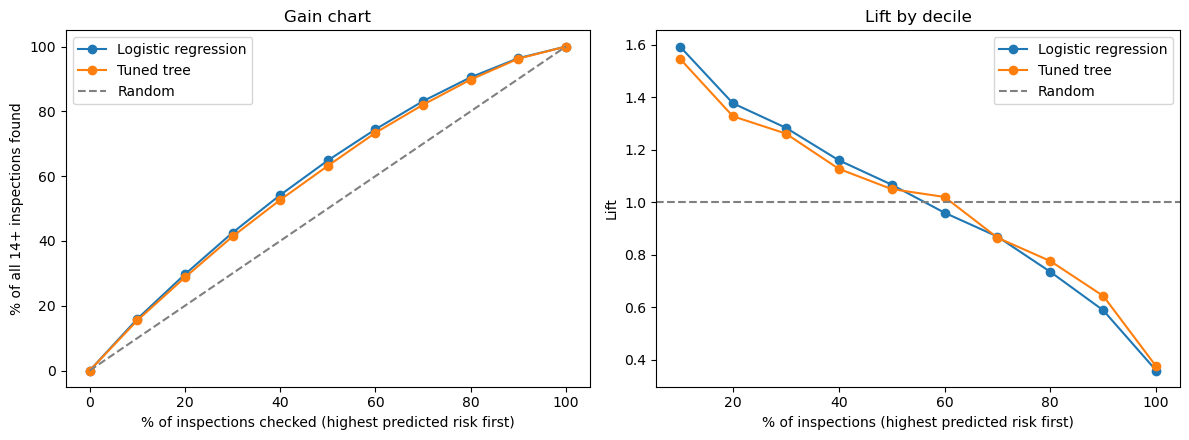

In [20]:
# Gain and lift for logistic regression and the tuned tree
def gain_lift(y_true, p, n_bins=10):
    t = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p)})
    t = t.sort_values("p", ascending=False).reset_index(drop=True)
    t["decile"] = np.floor(np.arange(len(t)) * n_bins / len(t)).astype(int) + 1
    g = t.groupby("decile")["y"].agg(["size", "sum"])
    g["gain"] = g["sum"].cumsum() / t["y"].sum()
    g["lift"] = (g["sum"] / g["size"]) / t["y"].mean()
    return g

gl_logit = gain_lift(y_test, p_logit)
gl_tree = gain_lift(y_test, p_tuned2)
print("Logistic regression"); print(gl_logit.round(3))
print("Tuned tree"); print(gl_tree.round(3))

x = np.arange(1, 11) * 10
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot([0] + list(x), [0] + list(gl_logit["gain"] * 100), marker="o", label="Logistic regression")
ax[0].plot([0] + list(x), [0] + list(gl_tree["gain"] * 100), marker="o", label="Tuned tree")
ax[0].plot([0, 100], [0, 100], "--", color="gray", label="Random")
ax[0].set_title("Gain chart")
ax[0].set_xlabel("% of inspections checked (highest predicted risk first)")
ax[0].set_ylabel("% of all 14+ inspections found")
ax[0].legend()

ax[1].plot(x, gl_logit["lift"], marker="o", label="Logistic regression")
ax[1].plot(x, gl_tree["lift"], marker="o", label="Tuned tree")
ax[1].axhline(1, linestyle="--", color="gray", label="Random")
ax[1].set_title("Lift by decile")
ax[1].set_xlabel("% of inspections (highest predicted risk first)")
ax[1].set_ylabel("Lift")
ax[1].legend()

plt.tight_layout()
plt.show()

In [21]:
# Robustness check: split by restaurant instead of by inspection
ids_train, ids_test = train_test_split(d["CAMIS"].unique(), test_size=0.3, random_state=42)
g_train = d.index[d["CAMIS"].isin(ids_train)]
g_test = d.index[d["CAMIS"].isin(ids_test)]
print("Rows: train", len(g_train), "| test", len(g_test))
print("Restaurants in both sets:", len(set(d.loc[g_train, "CAMIS"]) & set(d.loc[g_test, "CAMIS"])))

Xg_train, Xg_test = X.loc[g_train].copy(), X.loc[g_test].copy()
med_g = Xg_train.median()
Xg_train, Xg_test = Xg_train.fillna(med_g), Xg_test.fillna(med_g)
keep_g = [c for c in Xg_train.columns
          if c in cont or (Xg_train[c].nunique() > 1 and Xg_train[c].sum() >= 50)]
Xg_train, Xg_test = Xg_train[keep_g].copy(), Xg_test[keep_g].copy()
mu_g, sd_g = Xg_train[cont].mean(), Xg_train[cont].std()
Xg_train[cont] = (Xg_train[cont] - mu_g) / sd_g
Xg_test[cont] = (Xg_test[cont] - mu_g) / sd_g

yg_train, yg_test = y_14plus.loc[g_train], y_14plus.loc[g_test]
yg_train_log, yg_test_log = y_log.loc[g_train], y_log.loc[g_test]
Xgc_train = sm.add_constant(Xg_train.astype(float))
Xgc_test = sm.add_constant(Xg_test.astype(float), has_constant="add")

try:
    logit_g = sm.Logit(yg_train, Xgc_train).fit(maxiter=200, disp=0)
except Exception:
    logit_g = sm.Logit(yg_train, Xgc_train).fit(method="bfgs", maxiter=2000, disp=0)
p_g = logit_g.predict(Xgc_test)
ols_g = sm.OLS(yg_train_log, Xgc_train).fit()
pred_g = ols_g.predict(Xgc_test)

print("Logistic regression: split by inspection | split by restaurant")
print("  AUC:", round(roc_auc_score(y_test, p_logit), 3), "|", round(roc_auc_score(yg_test, p_g), 3))
print("  Accuracy at 0.5:", round(accuracy_score(y_test, pred_logit), 3), "|",
      round(accuracy_score(yg_test, (p_g >= 0.5).astype(int)), 3))
print("  Baseline accuracy:", round(max(y_test.mean(), 1 - y_test.mean()), 3), "|",
      round(max(yg_test.mean(), 1 - yg_test.mean()), 3))
print("Linear regression on LOG_SCORE")
print(pd.DataFrame({"Split by inspection": scores(y_test_log, pred_log),
                    "Split by restaurant": scores(yg_test_log, pred_g)}).T.round(3))

Rows: train 54818 | test 23431
Restaurants in both sets: 0
Logistic regression: split by inspection | split by restaurant
  AUC: 0.674 | 0.668
  Accuracy at 0.5: 0.638 | 0.636
  Baseline accuracy: 0.595 | 0.597
Linear regression on LOG_SCORE
                      RMSE    MAE     R2
Split by inspection  0.687  0.525  0.262
Split by restaurant  0.684  0.524  0.268


In [22]:
# Sensitivity check: routine Cycle / Initial inspections only
is_cy = d["INSPECTION TYPE"] == "Cycle Inspection / Initial Inspection"
cy_train = train_idx[is_cy.loc[train_idx].values]
cy_test = test_idx[is_cy.loc[test_idx].values]
print("Rows: train", len(cy_train), "| test", len(cy_test))
print("SCORE_14PLUS rate (train):", round(y_14plus.loc[cy_train].mean() * 100, 1), "%")

Xy_train, Xy_test = X.loc[cy_train].copy(), X.loc[cy_test].copy()
med_cy = Xy_train.median()
Xy_train, Xy_test = Xy_train.fillna(med_cy), Xy_test.fillna(med_cy)
keep_cy = [c for c in Xy_train.columns
           if c in cont or (Xy_train[c].nunique() > 1 and Xy_train[c].sum() >= 50)]
Xy_train, Xy_test = Xy_train[keep_cy].copy(), Xy_test[keep_cy].copy()
mu_cy, sd_cy = Xy_train[cont].mean(), Xy_train[cont].std()
Xy_train[cont] = (Xy_train[cont] - mu_cy) / sd_cy
Xy_test[cont] = (Xy_test[cont] - mu_cy) / sd_cy

ycy_train, ycy_test = y_14plus.loc[cy_train], y_14plus.loc[cy_test]
ycy_train_log, ycy_test_log = y_log.loc[cy_train], y_log.loc[cy_test]
Xycon_train = sm.add_constant(Xy_train.astype(float))
Xycon_test = sm.add_constant(Xy_test.astype(float), has_constant="add")

try:
    logit_cy = sm.Logit(ycy_train, Xycon_train).fit(maxiter=200, disp=0)
except Exception:
    logit_cy = sm.Logit(ycy_train, Xycon_train).fit(method="bfgs", maxiter=2000, disp=0)
p_cy = logit_cy.predict(Xycon_test)
ols_cy = sm.OLS(ycy_train_log, Xycon_train).fit()
pred_cy = ols_cy.predict(Xycon_test)

print("Logistic regression (Cycle / Initial only)")
print("  AUC:", round(roc_auc_score(ycy_test, p_cy), 3))
print("  Accuracy at 0.5:", round(accuracy_score(ycy_test, (p_cy >= 0.5).astype(int)), 3),
      "| baseline:", round(max(ycy_test.mean(), 1 - ycy_test.mean()), 3))
print("Linear regression on LOG_SCORE (Cycle / Initial only)")
print(pd.DataFrame({"Baseline (training mean)": scores(ycy_test_log, np.full(len(ycy_test_log), ycy_train_log.mean())),
                    "Linear regression": scores(ycy_test_log, pred_cy)}).T.round(3))

top_l = pd.DataFrame({"coef": logit_cy.params, "odds_ratio": np.exp(logit_cy.params),
                      "abs_z": logit_cy.tvalues.abs()}).drop("const")
print("Top 10 logistic predictors"); print(top_l.sort_values("abs_z", ascending=False).head(10).round(3))
top_o = pd.DataFrame({"coef": ols_cy.params, "abs_t": ols_cy.tvalues.abs()}).drop("const")
print("Top 10 linear regression predictors"); print(top_o.sort_values("abs_t", ascending=False).head(10).round(3))

Rows: train 30696 | test 13215
SCORE_14PLUS rate (train): 40.4 %
Logistic regression (Cycle / Initial only)
  AUC: 0.671
  Accuracy at 0.5: 0.641 | baseline: 0.604
Linear regression on LOG_SCORE (Cycle / Initial only)
                           RMSE    MAE     R2
Baseline (training mean)  0.706  0.542 -0.000
Linear regression         0.663  0.511  0.119
Top 10 logistic predictors
                      coef  odds_ratio   abs_z
days_since_first    -0.783       0.457  21.936
n_prior_inspections  0.466       1.594  16.458
chain               -0.515       0.597  13.637
cuisine_Coffee/Tea  -0.565       0.569  11.089
year                 0.202       1.224  10.750
cuisine_American    -0.347       0.707   9.117
cuisine_Donuts      -0.755       0.470   8.478
days_since_last      0.158       1.171   8.075
has_history          0.392       1.480   7.524
cuisine_Hamburgers  -0.655       0.520   6.749
Top 10 linear regression predictors
                      coef   abs_t
days_since_first    -0.222  2

In [23]:
# PART G: Comparison tables for all models (same test rows)
from sklearn.metrics import precision_score, recall_score, f1_score

def clf_row(y_true, p, pred):
    return {"AUC": roc_auc_score(y_true, p),
            "Accuracy": accuracy_score(y_true, pred),
            "Precision 14+": precision_score(y_true, pred),
            "Recall 14+": recall_score(y_true, pred),
            "F1 14+": f1_score(y_true, pred)}

clf_table = pd.DataFrame({
    "Logistic regression (cutoff 0.5)": clf_row(y_test, p_logit, pred_logit),
    "Logistic regression (cutoff 0.411)": clf_row(y_test, p_logit, pred_cut),
    "Classification tree (depth 4)": clf_row(y_test, p_tree, pred_tree),
    "Classification tree (tuned, first grid)": clf_row(y_test, p_tuned, pred_tuned),
    "Classification tree (tuned, wider grid)": clf_row(y_test, p_tuned2, pred_tuned2)}).T
print("Classification of SCORE_14PLUS (baseline accuracy, always score 0-13):",
      round(1 - y_test.mean(), 3))
print(clf_table.round(3))

models_log = {"Baseline (training mean)": base_log,
              "Linear regression": pred_log,
              "Regression tree (depth 4)": pred_tree_log,
              "Regression tree (tuned)": pred_tree_tuned2}
models_score = {"Baseline (training mean)": np.full(len(y_test_score), base_score),
                "Linear regression": np.asarray(pred_score),
                "Regression tree (depth 4)": np.expm1(pred_tree_log).clip(min=0),
                "Regression tree (tuned)": np.expm1(pred_tree_tuned2).clip(min=0)}
reg_log = pd.DataFrame({k: scores(y_test_log, np.asarray(v)) for k, v in models_log.items()}).T
reg_score = pd.DataFrame({k: scores(y_test_score, np.asarray(v)) for k, v in models_score.items()}).T
print("Regression on the LOG_SCORE scale"); print(reg_log.round(3))
print("Regression on the original SCORE scale"); print(reg_score.round(3))

Classification of SCORE_14PLUS (baseline accuracy, always score 0-13): 0.595
                                           AUC  Accuracy  Precision 14+  \
Logistic regression (cutoff 0.5)         0.674     0.638          0.583   
Logistic regression (cutoff 0.411)       0.674     0.621          0.527   
Classification tree (depth 4)            0.600     0.610          0.567   
Classification tree (tuned, first grid)  0.655     0.630          0.593   
Classification tree (tuned, wider grid)  0.658     0.632          0.569   

                                         Recall 14+  F1 14+  
Logistic regression (cutoff 0.5)              0.372   0.454  
Logistic regression (cutoff 0.411)            0.640   0.578  
Classification tree (depth 4)                 0.154   0.243  
Classification tree (tuned, first grid)       0.272   0.373  
Classification tree (tuned, wider grid)       0.374   0.451  
Regression on the LOG_SCORE scale
                            RMSE    MAE     R2
Baseline (training 

In [24]:
# Restaurant-level compliance indicator (Question 3a)
cols = ["CAMIS", "BORO", "CUISINE DESCRIPTION", "inspections_with_score",
        "first_inspection_date", "most_recent_inspection_date",
        "average_score", "a_range_score_pct", "critical_violation_count"]
rh = pd.read_csv("data/restaurant_history.csv", usecols=cols,
                 parse_dates=["first_inspection_date", "most_recent_inspection_date"])
n_all = len(rh)

rh = rh[rh["inspections_with_score"] >= 2].copy()
years = ((rh["most_recent_inspection_date"] - rh["first_inspection_date"]).dt.days / 365.25).clip(lower=1)
rh["avg_score"] = rh["average_score"]
rh["share_A"] = rh["a_range_score_pct"]
rh["critical_per_year"] = rh["critical_violation_count"] / years
rh["critical_per_inspection"] = rh["critical_violation_count"] / rh["inspections_with_score"]
ind = ["avg_score", "share_A", "critical_per_year", "critical_per_inspection"]

print("Restaurants kept (2+ scored inspections):", len(rh), "of", n_all)
print(rh[ind].describe().round(2))
print(rh[ind].corr().round(2))

Restaurants kept (2+ scored inspections): 23487 of 31366
       avg_score   share_A  critical_per_year  critical_per_inspection
count   23487.00  23487.00           23487.00                 23487.00
mean       17.04     63.06               3.19                     1.79
std         8.97     31.26               2.57                     0.95
min         0.00      0.00               0.00                     0.00
25%        10.50     40.00               1.40                     1.00
50%        15.33     66.67               2.51                     1.67
75%        22.00    100.00               4.15                     2.33
max       113.50    100.00              30.00                     8.50
                         avg_score  share_A  critical_per_year  \
avg_score                     1.00    -0.80               0.81   
share_A                      -0.80     1.00              -0.71   
critical_per_year             0.81    -0.71               1.00   
critical_per_inspection       0.88    -0

In [25]:
# Combine the measures into one compliance index (Question 3a)
parts = rh[["avg_score", "share_A", "critical_per_year"]]
z = (parts - parts.mean()) / parts.std()
rh["compliance_index"] = (-z["avg_score"] + z["share_A"] - z["critical_per_year"]) / 3
rh["compliance_group"] = pd.qcut(rh["compliance_index"], 4,
                                 labels=["Lowest 25%", "Low-mid 25%", "High-mid 25%", "Highest 25%"])

print(rh["compliance_index"].describe().round(2))
print(rh.groupby("compliance_group", observed=True)[["avg_score", "share_A", "critical_per_year"]].mean().round(2))

def by_group(col, min_n=100):
    g = rh.groupby(col).agg(restaurants=("CAMIS", "size"),
                            mean_index=("compliance_index", "mean"),
                            avg_score=("avg_score", "mean"),
                            share_A=("share_A", "mean"))
    return g[g["restaurants"] >= min_n].sort_values("mean_index", ascending=False).round(2)

print(by_group("BORO"))
by_cuisine = by_group("CUISINE DESCRIPTION")
print("Best cuisines"); print(by_cuisine.head(8))
print("Weakest cuisines"); print(by_cuisine.tail(8))

count    23487.00
mean         0.00
std          0.92
min         -6.05
25%         -0.56
50%          0.12
75%          0.84
max          1.44
Name: compliance_index, dtype: float64
                  avg_score  share_A  critical_per_year
compliance_group                                       
Lowest 25%            28.74    24.12               6.44
Low-mid 25%           18.63    51.91               3.34
High-mid 25%          12.86    76.29               2.03
Highest 25%            7.94    99.94               0.94
               restaurants  mean_index  avg_score  share_A
BORO                                                      
Manhattan             9129        0.08      16.38    65.13
Staten Island          850        0.04      16.49    61.11
Brooklyn              6025        0.00      17.15    63.47
Bronx                 2061       -0.03      16.98    61.33
Queens                5394       -0.13      18.16    60.06
Best cuisines
                                restaurants  mean_inde

In [26]:
# Variable summary across the four models (Question 3b)
cols_all = X_train.columns
imp_table = pd.DataFrame({
    "logistic": res["abs_z"].reindex(cols_all),
    "linear": res_ols["abs_t"].reindex(cols_all),
    "class_tree": pd.Series(tree_tuned2.feature_importances_, index=cols_all),
    "reg_tree": pd.Series(tree_log_tuned2.feature_importances_, index=cols_all)})

ranks = imp_table.rank(ascending=False)
summary = ranks.copy()
summary["mean_rank"] = ranks.mean(axis=1)

sign_l = np.sign(res["coef"].reindex(cols_all))
sign_o = np.sign(res_ols["coef"].reindex(cols_all))
summary["direction"] = np.where(sign_l == sign_o,
                                np.where(sign_l > 0, "higher score", "lower score"), "mixed")
summary = summary.sort_values("mean_rank")
print("Rank of each variable in each model (1 = most important)")
print(summary.head(15).round(1))

top10 = [set(ranks[c].nsmallest(10).index) for c in ranks.columns]
print("In the top 10 of all four models:", sorted(set.intersection(*top10)))
print("In the top 10 of at least three models:",
      sorted(v for v in cols_all if sum(v in s for s in top10) >= 3))

Rank of each variable in each model (1 = most important)
                                                    logistic  linear  \
chain                                                    5.0     4.0   
INSPECTION TYPE_Inter-Agency Task Force / Initi...       9.0     1.0   
days_since_first                                         2.0     5.0   
n_prior_inspections                                      3.0     6.0   
INSPECTION TYPE_Cycle Inspection / Re-inspection         4.0     8.0   
INSPECTION TYPE_Cycle Inspection / Reopening In...       1.0     2.0   
days_since_last                                         13.0    18.0   
cuisine_Coffee/Tea                                      10.0     7.0   
year                                                     7.0     9.0   
INSPECTION TYPE_Pre-permit (Operational) / Reop...       6.0     3.0   
INSPECTION TYPE_Pre-permit (Operational) / Init...      20.0    12.0   
cuisine_Donuts                                          11.0    11.0   
cuisine

In [27]:
# PART H: Survival analysis (Kaplan-Meier and Cox)
# Build the survival table, one row per restaurant

sv_rows = d.sort_values(["CAMIS", "INSPECTION DATE"]).copy()
sv_rows["k"] = sv_rows.groupby("CAMIS").cumcount()      # 0 = first scored inspection

# time zero = first scored inspection (take that exact row, not .first())
first_row = sv_rows[sv_rows["k"] == 0].set_index("CAMIS")

# event = first LATER inspection with score 14+
later_fail = sv_rows[(sv_rows["k"] > 0) & (sv_rows["SCORE_14PLUS"] == 1)]
fail_date = later_fail.groupby("CAMIS")["INSPECTION DATE"].min()
last_date = sv_rows.groupby("CAMIS")["INSPECTION DATE"].max()

surv = pd.DataFrame({
    "start": first_row["INSPECTION DATE"],
    "n_scored": sv_rows.groupby("CAMIS").size(),
    "last_date": last_date,
})
surv["fail_date"] = fail_date
surv["event"] = surv["fail_date"].notna().astype(int)
surv["end"] = surv["fail_date"].fillna(surv["last_date"])
surv["days"] = (surv["end"] - surv["start"]).dt.days

# facts known at time zero only
surv["first_score"] = first_row["SCORE"]
surv["first_14plus"] = first_row["SCORE_14PLUS"].astype(int)
for c in ["BORO", "cuisine", "chain", "INSPECTION TYPE",
          "median_hh_income", "population", "bldg_age"]:
    surv[c] = first_row[c]

# check before dropping anything
print("Restaurants in total:", len(surv))
print("Only 1 scored inspection:", int((surv["n_scored"] == 1).sum()))
print("2 or more scored, but 0 days follow-up:",
      int(((surv["n_scored"] >= 2) & (surv["days"] == 0)).sum()))

# keep restaurants that have some follow-up time
surv = surv[(surv["n_scored"] >= 2) & (surv["days"] > 0)].copy()

print("\nRestaurants kept:", len(surv))
print("Events (reached 14+):", int(surv["event"].sum()),
      "| Censored:", int((surv["event"] == 0).sum()))
print("Event share:", round(surv["event"].mean() * 100, 1), "%")
print("\nDays of follow-up:")
print(surv["days"].describe().round(1))
print("\nEvent share by first inspection result:")
print(surv.groupby("first_14plus")["event"].agg(["count", "mean"]).round(3))

Restaurants in total: 27315
Only 1 scored inspection: 4448
2 or more scored, but 0 days follow-up: 0

Restaurants kept: 22867
Events (reached 14+): 11820 | Censored: 11047
Event share: 51.7 %

Days of follow-up:
count    22867.0
mean       558.3
std        287.4
min          1.0
25%        374.0
50%        565.0
75%        769.0
max       1095.0
Name: days, dtype: float64

Event share by first inspection result:
              count   mean
first_14plus              
0             12312  0.411
1             10555  0.640


In [28]:
# Package versions used for this notebook
# The survival part needs lifelines. If it is missing, run once in a terminal: pip install lifelines
# Then restart the kernel, because the install can upgrade pandas.
import matplotlib, pandas, lifelines
print(matplotlib.__version__, pandas.__version__, lifelines.__version__)

3.7.2 2.3.3 0.30.3


All restaurants | n: 22867 | median days until 14+: 723.0 | share still below 14 at 365 days: 0.81
Chain | n: 3817 | median days until 14+: 973.0 | share still below 14 at 365 days: 0.869
Not chain | n: 19050 | median days until 14+: 679.0 | share still below 14 at 365 days: 0.797


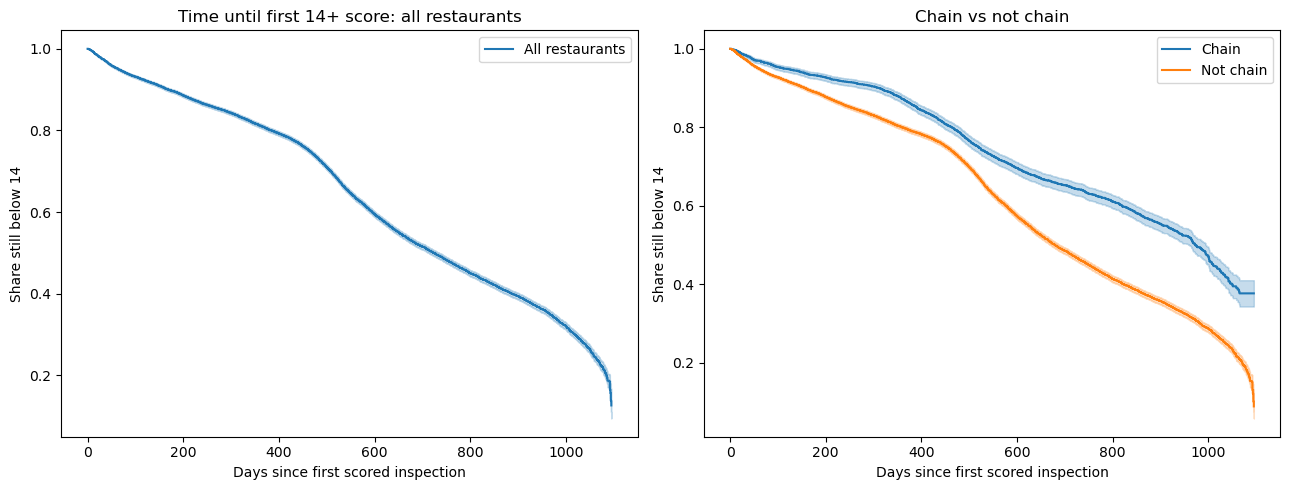

In [29]:
# Kaplan-Meier curves: all restaurants, then chain vs not chain

import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# left: all restaurants
kmf.fit(durations=surv["days"], event_observed=surv["event"], label="All restaurants")
kmf.plot_survival_function(ax=axes[0])
print("All restaurants | n:", len(surv),
      "| median days until 14+:", kmf.median_survival_time_,
      "| share still below 14 at 365 days:", round(float(kmf.predict(365)), 3))
axes[0].set_title("Time until first 14+ score: all restaurants")
axes[0].set_xlabel("Days since first scored inspection")
axes[0].set_ylabel("Share still below 14")

# right: chain vs not chain
for flag, name in [(1, "Chain"), (0, "Not chain")]:
    m = surv["chain"] == flag
    kmf.fit(durations=surv.loc[m, "days"], event_observed=surv.loc[m, "event"], label=name)
    kmf.plot_survival_function(ax=axes[1])
    print(name, "| n:", int(m.sum()),
          "| median days until 14+:", kmf.median_survival_time_,
          "| share still below 14 at 365 days:", round(float(kmf.predict(365)), 3))
axes[1].set_title("Chain vs not chain")
axes[1].set_xlabel("Days since first scored inspection")
axes[1].set_ylabel("Share still below 14")

plt.tight_layout()
plt.show()

First score below 14 | n: 12312 | median days until 14+: 938.0 | share still below 14 at 365 days: 0.957
First score 14+ | n: 10555 | median days until 14+: 547.0 | share still below 14 at 365 days: 0.624

                  n  median_days  reached_1yr  reached_2yr
BORO                                                      
Manhattan      8883        772.0        0.163        0.473
Brooklyn       5861        733.0        0.200        0.499
Queens         5252        659.0        0.216        0.548
Bronx          2043        642.0        0.215        0.547
Staten Island   828        728.0        0.191        0.505


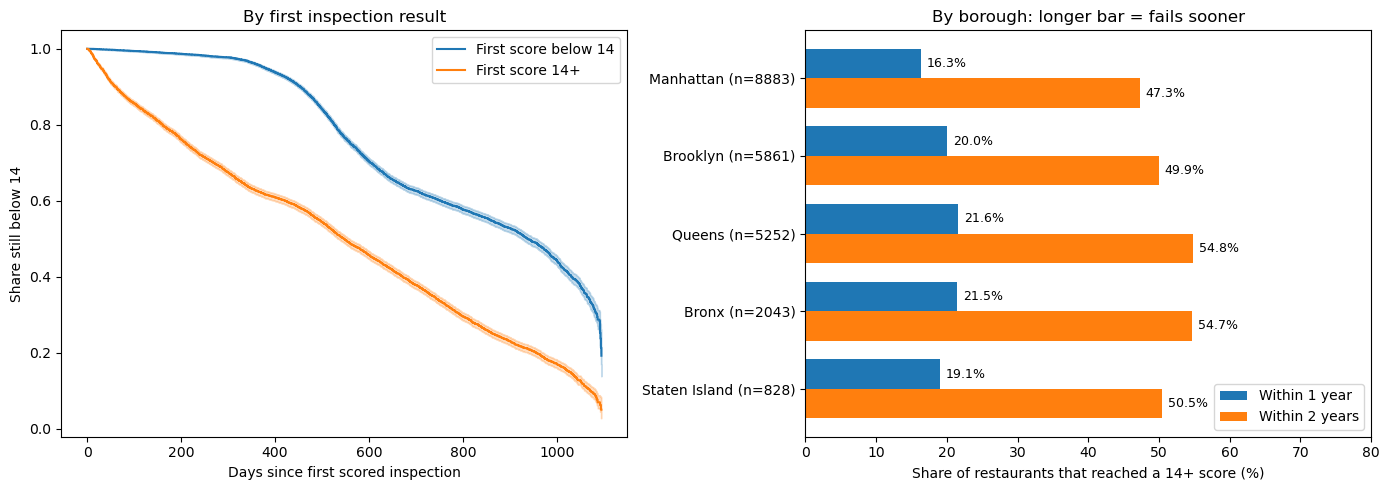

In [30]:
# Kaplan-Meier: first inspection result (curves) and borough (bar chart)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: curves by first inspection result
for value, name in [(0, "First score below 14"), (1, "First score 14+")]:
    m = surv["first_14plus"] == value
    kmf.fit(durations=surv.loc[m, "days"], event_observed=surv.loc[m, "event"], label=name)
    kmf.plot_survival_function(ax=axes[0])
    print(name, "| n:", int(m.sum()),
          "| median days until 14+:", kmf.median_survival_time_,
          "| share still below 14 at 365 days:", round(float(kmf.predict(365)), 3))
axes[0].set_title("By first inspection result")
axes[0].set_xlabel("Days since first scored inspection")
axes[0].set_ylabel("Share still below 14")

# right: share that reached 14+ within 1 and 2 years, by borough
rows = []
for b in surv["BORO"].value_counts().index:
    m = surv["BORO"] == b
    kmf.fit(durations=surv.loc[m, "days"], event_observed=surv.loc[m, "event"])
    rows.append({"BORO": b, "n": int(m.sum()),
                 "median_days": kmf.median_survival_time_,
                 "reached_1yr": 1 - float(kmf.predict(365)),
                 "reached_2yr": 1 - float(kmf.predict(730))})
bor = pd.DataFrame(rows).set_index("BORO")
print()
print(bor.round(3))

y = np.arange(len(bor))
h = 0.38
axes[1].barh(y - h / 2, bor["reached_1yr"] * 100, height=h, label="Within 1 year")
axes[1].barh(y + h / 2, bor["reached_2yr"] * 100, height=h, label="Within 2 years")
for i, (a, c) in enumerate(zip(bor["reached_1yr"], bor["reached_2yr"])):
    axes[1].text(a * 100 + 0.8, i - h / 2, f"{a * 100:.1f}%", va="center", fontsize=9)
    axes[1].text(c * 100 + 0.8, i + h / 2, f"{c * 100:.1f}%", va="center", fontsize=9)
axes[1].set_yticks(y)
axes[1].set_yticklabels([f"{b} (n={n})" for b, n in zip(bor.index, bor["n"])])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 80)
axes[1].set_xlabel("Share of restaurants that reached a 14+ score (%)")
axes[1].set_title("By borough: longer bar = fails sooner")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [31]:
# Prepare the Cox model table (predictors known at time zero)

import pandas as pd

# 1) time, event and the simple predictors
cox_df = surv[["days", "event", "first_14plus", "chain"]].copy()
cox_df["chain"] = cox_df["chain"].astype(int)

# 2) building and Census: known flags, median fill, standardize
num = surv[["median_hh_income", "population", "bldg_age"]].copy()
cox_df["income_known"] = num["median_hh_income"].notna().astype(int)
cox_df["bldg_known"] = num["bldg_age"].notna().astype(int)
num = num.fillna(num.median())
num = (num - num.mean()) / num.std()
num.columns = ["income_z", "population_z", "bldg_age_z"]
cox_df = cox_df.join(num)

# 3) categories to 0/1 columns, most common category as reference
cats = surv[["BORO", "cuisine", "INSPECTION TYPE"]].copy()
print("First inspection types (restaurants):")
print(cats["INSPECTION TYPE"].value_counts())
print()

dummies = pd.get_dummies(cats, dtype=int)
for var in ["BORO", "cuisine", "INSPECTION TYPE"]:
    ref = cats[var].value_counts().index[0]
    dummies = dummies.drop(columns=f"{var}_{ref}")
    print("Reference for", var, ":", ref)

# drop rare dummy columns (fewer than 50 restaurants)
rare = dummies.columns[dummies.sum() < 50]
print("\nRare columns dropped:", len(rare))
print(list(rare))
dummies = dummies.drop(columns=rare)
cox_df = cox_df.join(dummies)

# 4) checks
predictors = [c for c in cox_df.columns if c not in ["days", "event"]]
print("\nCox table shape:", cox_df.shape)
print("Number of predictors:", len(predictors))
print("Missing values:", int(cox_df.isna().sum().sum()))
print("Constant columns:", [c for c in predictors if cox_df[c].nunique() == 1])
print("Events:", int(cox_df["event"].sum()),
      "| events per predictor:", round(cox_df["event"].sum() / len(predictors)))
print("\nPredictors:")
print(predictors)

First inspection types (restaurants):
INSPECTION TYPE
Cycle Inspection / Initial Inspection                      13268
Pre-permit (Operational) / Initial Inspection               6520
Cycle Inspection / Re-inspection                            2217
Pre-permit (Non-operational) / Initial Inspection            662
Pre-permit (Operational) / Re-inspection                     105
Inter-Agency Task Force / Initial Inspection                  62
Cycle Inspection / Compliance Inspection                      13
Pre-permit (Operational) / Compliance Inspection               8
Cycle Inspection / Reopening Inspection                        3
Pre-permit (Operational) / Second Compliance Inspection        3
Pre-permit (Non-operational) / Re-inspection                   3
Cycle Inspection / Second Compliance Inspection                2
Pre-permit (Operational) / Reopening Inspection                1
Name: count, dtype: int64

Reference for BORO : Manhattan
Reference for cuisine : Other
Reference for

<lifelines.CoxPHFitter: fitted with 22867 total observations, 11047 right-censored observations>
             duration col = 'days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 22867
number of events observed = 11820
   partial log-likelihood = -108782.596
         time fit was run = 2026-11-25 06:10:02 UTC

---
                                                                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                                           
first_14plus                                                       0.829     2.290     0.019           0.791           0.866               2.206               2.378
chain                                                             -0.270     0.763     0.031          -0.331          -0.209               0.719               0.811
income_known                                                       0.210     1.233     0.086           0.041           0.378               1.042               1.459
bldg_known                                                         0.151     1.163     0.067           0.019           0.282               1.019               1.326
income_z                                                          -0.010     0.990     0.013          -0.035           0.015               0.966               1.015
population_z                                                       0.054     1.055     0.012           0.031           0.076               1.032               1.079
bldg_age_z                                                         0.049     1.050     0.010           0.029           0.069               1.029               1.071
BORO_Bronx                                                         0.117     1.124     0.039           0.040           0.194               1.041               1.214
BORO_Brooklyn                                                     -0.026     0.975     0.027          -0.079           0.028               0.924               1.028
BORO_Queens                                                        0.124     1.132     0.028           0.070           0.178               1.072               1.195
BORO_Staten Island                                                 0.139     1.149     0.052           0.038           0.240               1.038               1.271
cuisine_American                                                  -0.169     0.845     0.030          -0.227          -0.110               0.797               0.896
cuisine_Bakery Products/Desserts                                   0.018     1.018     0.051          -0.081           0.118               0.922               1.125
cuisine_Caribbean                                                  0.317     1.373     0.051           0.217           0.417               1.242               1.517
cuisine_Chicken                                                    0.050     1.051     0.060          -0.067           0.167               0.935               1.181
cuisine_Chinese                                                    0.132     1.141     0.034           0.065           0.198               1.068               1.220
cuisine_Coffee/Tea                                                -0.220     0.803     0.040          -0.299          -0.140               0.742               0.869
cuisine_Donuts                                                    -0.250     0.779     0.081          -0.408          -0.091               0.665               0.913
cuisine_Hamburgers                                                -0.312     0.732     0.085          -0.478          -0.146               0.620               0.864
cuisine_Italian                                                   -0.223     0.800     0.054          -0.328          -0.118               0.720               0.889
c


Concordance: 0.678
                                                                   hazard_ratio  lower_95  upper_95  p_value
covariate                                                                                                   
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection              3.004     2.198     4.106    0.000
first_14plus                                                              2.290     2.206     2.378    0.000
INSPECTION TYPE_Pre-permit (Operational) / Initial Inspection             1.504     1.441     1.569    0.000
INSPECTION TYPE_Pre-permit (Non-operational) / Initial Inspection         1.449     1.295     1.621    0.000
cuisine_Caribbean                                                         1.373     1.242     1.517    0.000
income_known                                                              1.233     1.042     1.459    0.015
INSPECTION TYPE_Cycle Inspection / Re-inspection                          1.226     1.158     1.298    0.000

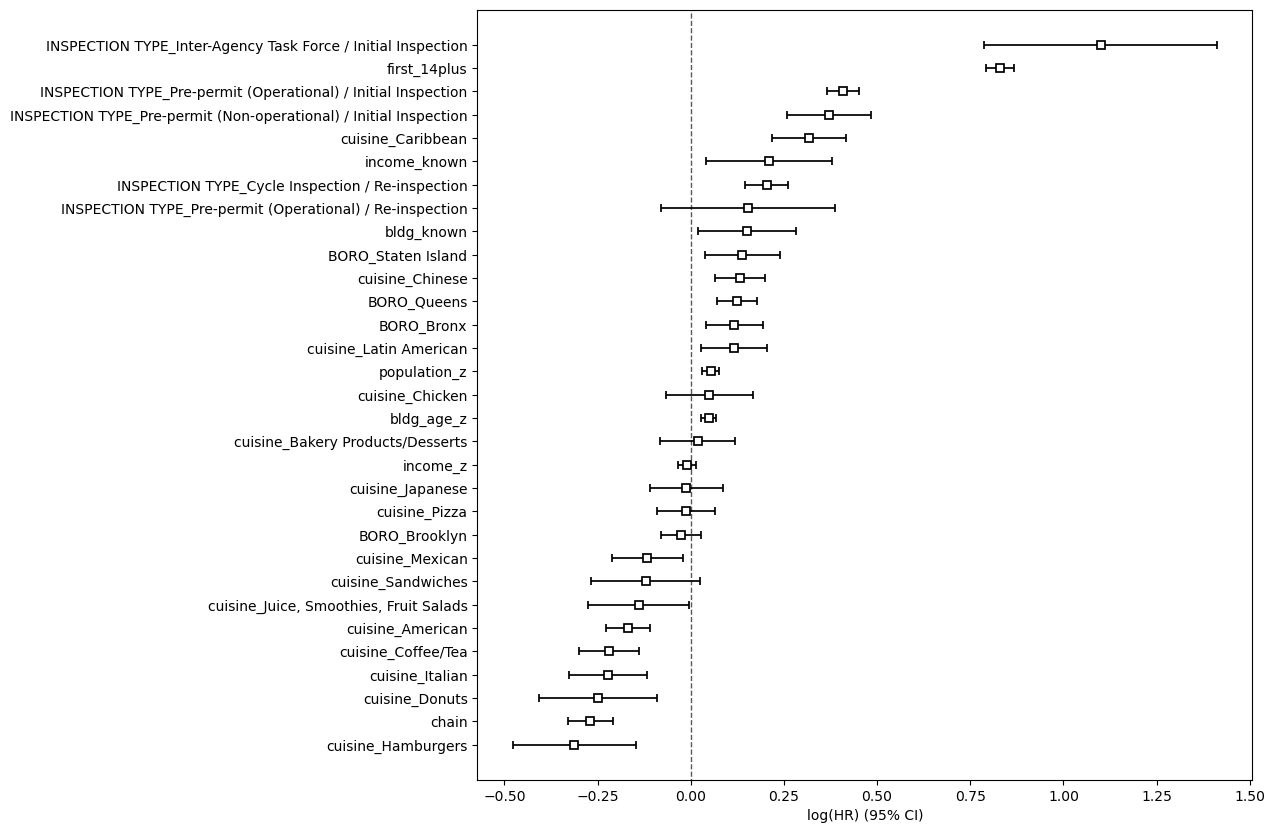

In [32]:
# Fit the Cox model and read the hazard ratios

from lifelines import CoxPHFitter
import matplotlib.pyplot as plt

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="days", event_col="event")
cph.print_summary(decimals=3)

# short table: hazard ratios, sorted from fastest to slowest to fail
hr = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].copy()
hr.columns = ["hazard_ratio", "lower_95", "upper_95", "p_value"]
print("\nConcordance:", round(cph.concordance_index_, 3))
print(hr.sort_values("hazard_ratio", ascending=False).round(3).to_string())

# coefficient plot (log hazard ratio with 95% range)
plt.subplots(figsize=(10, 10))
cph.plot()
plt.show()

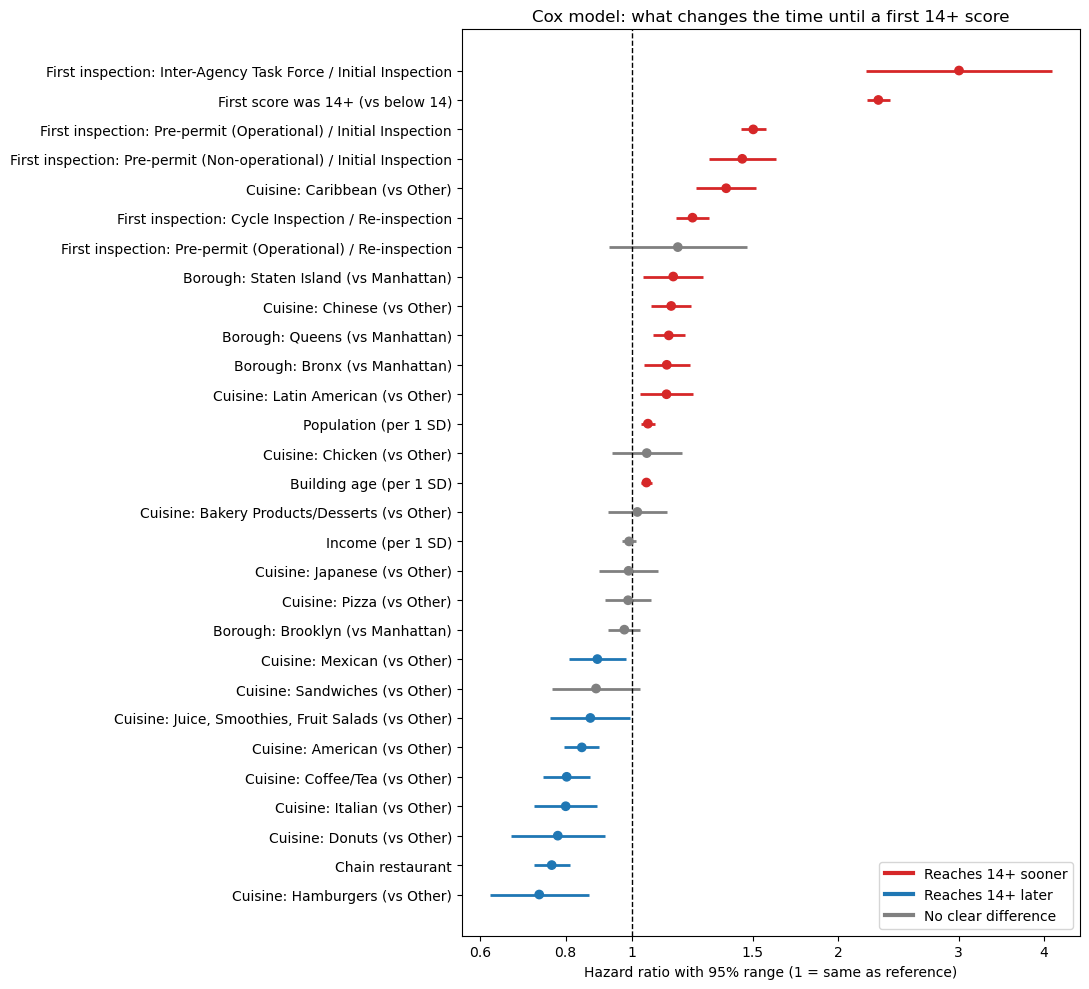

In [33]:
# Cleaner Cox plot: hazard ratios with plain labels

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def nice(name):
    if name.startswith("INSPECTION TYPE_"):
        return "First inspection: " + name.replace("INSPECTION TYPE_", "")
    if name.startswith("BORO_"):
        return "Borough: " + name[5:] + " (vs Manhattan)"
    if name.startswith("cuisine_"):
        return "Cuisine: " + name[8:] + " (vs Other)"
    return {"first_14plus": "First score was 14+ (vs below 14)",
            "chain": "Chain restaurant",
            "income_z": "Income (per 1 SD)",
            "population_z": "Population (per 1 SD)",
            "bldg_age_z": "Building age (per 1 SD)"}.get(name, name)

s = cph.summary.drop(index=["income_known", "bldg_known"]).copy()
s["label"] = [nice(n) for n in s.index]
s = s.sort_values("exp(coef)")

lo, hi, hr_ = s["exp(coef) lower 95%".replace("exp(coef) ", "exp(coef) ")], s["exp(coef) upper 95%"], s["exp(coef)"]
colors = np.where(lo > 1, "tab:red", np.where(hi < 1, "tab:blue", "gray"))

fig, ax = plt.subplots(figsize=(11, 10))
y = np.arange(len(s))
ax.hlines(y, lo, hi, color=colors, linewidth=2)
ax.scatter(hr_, y, color=colors, zorder=3)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.minorticks_off()
ticks = [0.6, 0.8, 1, 1.5, 2, 3, 4]
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.set_yticks(y)
ax.set_yticklabels(s["label"])
ax.set_xlabel("Hazard ratio with 95% range (1 = same as reference)")
ax.set_title("Cox model: what changes the time until a first 14+ score")
ax.legend(handles=[Line2D([0], [0], color="tab:red", lw=3, label="Reaches 14+ sooner"),
                   Line2D([0], [0], color="tab:blue", lw=3, label="Reaches 14+ later"),
                   Line2D([0], [0], color="gray", lw=3, label="No clear difference")],
          loc="lower right")
plt.tight_layout()
plt.show()

In [34]:
# Compare Cox with logistic and linear regression (shared factors only)

import numpy as np
import pandas as pd

cox_s = cph.summary
pairs = {"income_z": "median_hh_income", "population_z": "population", "bldg_age_z": "bldg_age"}

def direction(coef, p, alpha=0.05):
    if p >= alpha:
        return "no clear"
    return "riskier" if coef > 0 else "safer"

rows = []
for c in cox_s.index:
    if c.startswith("INSPECTION TYPE_") or c in ["first_14plus", "income_known", "bldg_known"]:
        continue
    other = pairs.get(c, c)
    if other not in logit_14plus.params.index:
        print("Not in the logistic model:", c)
        continue
    cx = cox_s.loc[c]
    rows.append({
        "factor": c,
        "Cox HR": cx["exp(coef)"],
        "Cox": direction(cx["coef"], cx["p"]),
        "Logistic OR": np.exp(logit_14plus.params[other]),
        "Logistic": direction(logit_14plus.params[other], logit_14plus.pvalues[other]),
        "Linear coef": ols.params[other],
        "Linear": direction(ols.params[other], ols.pvalues[other])})

cmp_tbl = pd.DataFrame(rows).set_index("factor")

def agree(r):
    vals = set(r)
    if len(vals) == 1:
        return "none clear in any model" if "no clear" in vals else "all three agree"
    if "riskier" in vals and "safer" in vals:
        return "conflict"
    return "partly (some not clear)"

cmp_tbl["Agreement"] = cmp_tbl[["Cox", "Logistic", "Linear"]].apply(agree, axis=1)

print(cmp_tbl.round(3).to_string())
print()
print(cmp_tbl["Agreement"].value_counts())

                                        Cox HR       Cox  Logistic OR  Logistic  Linear coef    Linear                Agreement
factor                                                                                                                         
chain                                    0.763     safer        0.612     safer       -0.188     safer          all three agree
income_z                                 0.990  no clear        0.953     safer       -0.018     safer  partly (some not clear)
population_z                             1.055   riskier        1.021  no clear        0.003  no clear  partly (some not clear)
bldg_age_z                               1.050   riskier        1.040   riskier        0.017   riskier          all three agree
BORO_Bronx                               1.124   riskier        0.945  no clear       -0.031     safer                 conflict
BORO_Brooklyn                            0.975  no clear        0.860     safer       -0.058     safer  

In [35]:
# Group-by-group test: which group of factors matters most?
# Refit the logistic (SCORE_14PLUS) and linear (LOG_SCORE) models leaving out one group at a time.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, r2_score

cols = list(Xs_train.columns)
groups = {
    "Earlier history": ["prev_score", "prev_critical", "prev_total_viol", "days_since_last",
                        "n_prior_inspections", "days_since_first", "has_history"],
    "Inspection type": [c for c in cols if c.startswith("INSPECTION TYPE_")],
    "Cuisine and chain": ["chain"] + [c for c in cols if c.startswith("cuisine_")],
    "Location (borough)": [c for c in cols if c.startswith("BORO_")],
    "Building and Census": ["bldg_age", "numfloors", "unitstotal", "bldgarea", "lotarea", "bldg_known",
                            "median_hh_income", "population", "income_known"],
    "Time (year, month)": ["year", "month"],
}
groups = {g: [c for c in v if c in cols] for g, v in groups.items()}   # keep only columns that exist
assert sorted(sum(groups.values(), [])) == sorted(cols), "every column must be in exactly one group"

ylog_train, ylog_test = y_log.loc[train_idx], y_log.loc[test_idx]

def fit_eval(keep):
    lg = LogisticRegression(penalty=None, max_iter=5000, tol=1e-8).fit(Xs_train[keep], y_train)
    auc = roc_auc_score(y_test, lg.predict_proba(Xs_test[keep])[:, 1])
    A = np.column_stack([np.ones(len(Xs_train)), Xs_train[keep].values.astype(float)])
    b = np.linalg.lstsq(A, ylog_train.values, rcond=None)[0]
    pred = np.column_stack([np.ones(len(Xs_test)), Xs_test[keep].values.astype(float)]) @ b
    return auc, r2_score(ylog_test, pred)

full_auc, full_r2 = fit_eval(cols)
print("All factors: AUC", round(full_auc, 4), "| R2 (log score)", round(full_r2, 4))

rows = []
for g, gc in groups.items():
    auc_wo, r2_wo = fit_eval([c for c in cols if c not in gc])
    auc_only, r2_only = fit_eval(gc)
    rows.append({"group left out": g, "n columns": len(gc),
                 "AUC without": auc_wo, "AUC drop": full_auc - auc_wo, "AUC with only this group": auc_only,
                 "R2 without": r2_wo, "R2 drop": full_r2 - r2_wo, "R2 with only this group": r2_only})
group_test = pd.DataFrame(rows).set_index("group left out")
print(group_test.round(4).to_string())

All factors: AUC 0.6735 | R2 (log score) 0.2619
                     n columns  AUC without  AUC drop  AUC with only this group  R2 without  R2 drop  R2 with only this group
group left out                                                                                                               
Earlier history              7       0.6450    0.0285                    0.6019      0.2460   0.0159                   0.0340
Inspection type             10       0.6473    0.0262                    0.5693      0.0722   0.1896                   0.1965
Cuisine and chain           16       0.6513    0.0223                    0.5987      0.2373   0.0246                   0.0303
Location (borough)           4       0.6729    0.0006                    0.5284      0.2605   0.0013                   0.0044
Building and Census          9       0.6698    0.0037                    0.5496      0.2534   0.0084                   0.0154
Time (year, month)           2       0.6706    0.0029                 